# Demand shocks by size

How the model's response scales with the **magnitude** of the demand shock. The shock is the
preference shifter `theta` from `fixed_demand_shock.ipynb`, hitting for one period at `t=1`:

$$C_t = P_t^{\,\text{power}}\;\theta_t^{1/(\gamma+\eta)},\qquad \text{power}=-\frac{1+\eta}{\gamma+\eta}$$

with inflation read off the Euler equation. Calibration (`c`, `N`, `tau`) is unchanged from the
other `demand_stuff/` notebooks, so the paths here are directly comparable.

The one thing done differently: **the shock size is a parameter**, not a literal buried in a cell
(`theta_list[1] = 0.9` in one place, `0.97` in another, `0.7` in a third), so it can be swept.

Three results, in order:

1. **At a fixed rate the response is exactly proportional in logs.** Closed forms for both output
   and inflation are derived and checked to machine precision. Different shock levels give
   literally the same picture rescaled — there is no size-dependent shape.
2. **In net (percentage) terms it is not.** The impact inflation spike outgrows the reversal, so a
   demand contraction leaves a positive net drift in the price level that grows superlinearly:
   negligible at 1%, about 14% of the shock at 20%.
3. **Policy is where size genuinely bites.** The output-minimising rate is the steady-state rate at
   *every* magnitude — prices are pre-set, so policy cannot touch the impact trough. The
   inflation-minimising rate falls steeply with the shock, and does so in discrete steps because
   `tau` is integer-valued.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## Parameters

In [2]:
gamma = 1
eta   = 0.5
sigma = 5
beta_hh = 0.99

R_SS  = 0.01                      # steady-state / 'fixed' policy rate
beta  = 1 / (1.0 + R_SS)
beta1 = 1 / (1.0 + R_SS * np.exp(30 / (36.5 * 0.9)))
power = -((1 + eta) / (gamma + eta))

T_SHOCK     = 1                                   # period the shifter hits
SHOCK       = 0.97                                # baseline: 3% demand decline
SHOCK_SIZES = [0.99, 0.97, 0.95, 0.90]            # 1%, 3%, 5%, 10%
H           = 18                                  # common horizon for all paths

print(f'power = {power}, theta exponent = {1/(gamma+eta):.6f}')

power = -1.0, theta exponent = 0.666667


## Calibration

Unchanged: choose `c` so the mean gap between the time-to-produce implied by `beta` and by
`beta1` is one period, then round each firm's lag to whichever of `floor`/`ceil` maximises
$(\beta c)^{\tau}(\tau+N)$.

In [3]:
data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_list   = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-12:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta  * cv) - Nn; t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))

c = np.min(c_list[np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1))])
N = -data_tau - 1 / np.log(beta * c)


def round_tau(bc, N):
    '''Optimal integer production lag under an effective discount factor bc = beta*c.'''
    t = -1 / np.log(bc) - N
    t[t < 0] = 0
    tf, tc = np.floor(t), np.ceil(t)
    pc = bc ** tc * (tc + N)
    pf = bc ** tf * (tf + N)
    t[(pc - pf) > 0] = tc[(pc - pf) > 0]
    t[(pc - pf) < 0] = tf[(pc - pf) < 0]
    t[t < 0] = 0
    return t


tau = round_tau(beta * c, N)
print(f'c = {c:.7f}   {len(N)} firms   tau in [{tau.min():.0f}, {tau.max():.0f}]   '
      f'mean tau = {tau.mean():.4f}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_14505/2989764586.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data     = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   269 firms   tau in [0, 13]   mean tau = 2.8885


## The demand shock

`theta_path` builds the shifter, `solve` returns the output and inflation paths. The shock size
is an argument throughout — nothing downstream reads a hardcoded magnitude.

Note the sign convention on inflation: `price_inflation_ee` inverts the Euler equation for the
inflation rate that must prevail *given* the nominal rate and the consumption path. A one-period
demand contraction means consumption is expected to grow back, so the required real rate is low;
with the nominal rate fixed, impact inflation is therefore **positive**, and reverses the next
period. This is the same object the other `demand_stuff/` notebooks plot.

In [4]:
def consumption_function(P, theta):
    return P ** power * theta ** (1 / (gamma + eta))


def price_inflation_ee(P_0, P_1, theta_1, theta_0, r):
    cg = (consumption_function(P_1, theta_1) /
          consumption_function(P_0, theta_0)) ** gamma * (theta_1 / theta_0)
    return 1 / (cg / (beta_hh * (1 + r)))


def theta_path(shock, n=H, t_shock=T_SHOCK):
    '''One-period preference shifter: ones everywhere except t_shock.'''
    th = np.ones(n)
    th[t_shock] = shock
    return th


def solve(shock, P, r):
    '''Output and inflation deviations under a demand shock of the given size.'''
    th = theta_path(shock, len(P))
    Y  = consumption_function(P, th)
    Y  = Y / Y[0] - 1
    pi = np.array([price_inflation_ee(P[i], P[i + 1], th[i + 1], th[i], r)
                   for i in range(len(P) - 1)]) - 1
    return Y, pi


# at the steady-state rate no firm re-times, so the price index is flat
tprod  = np.array((beta * c) ** tau * (tau + N))
P_flat = np.full(H, (np.sum(1 / tprod ** (1 - sigma))) ** (1 / (1 - sigma)))

Y, pi = solve(SHOCK, P_flat, R_SS)
print(f'{100*(1-SHOCK):.0f}% demand decline: output trough {Y.min():.5f}, '
      f'impact inflation {pi[0]:.5f}, reversal {pi[1]:.5f}')

3% demand decline: output trough -0.02010, impact inflation 0.05197, reversal -0.04959


### Consistency with the existing notebooks

`fixed_demand_shock.ipynb` computes the same object with `theta_list[1] = 0.97` inline; this
reproduces it.

In [5]:
theta_list = np.ones_like(P_flat)
theta_list[1] = 0.97
cons_orig = np.array([consumption_function(P_flat[i], theta_list[i]) for i in range(len(P_flat))])
cons_orig = cons_orig / cons_orig[0] - 1

assert np.allclose(solve(0.97, P_flat, R_SS)[0], cons_orig)
print('matches the inline construction in fixed_demand_shock.ipynb '
      f'(max abs diff {np.abs(solve(0.97, P_flat, R_SS)[0] - cons_orig).max():.2e})')

matches the inline construction in fixed_demand_shock.ipynb (max abs diff 0.00e+00)


## Responses by shock size, rate fixed

In [6]:
print(f'{"shock":>7}{"Y trough":>12}{"pi impact":>12}{"pi reversal":>13}{"net drift":>12}')
print('-' * 56)
for s in SHOCK_SIZES:
    Y_s, pi_s = solve(s, P_flat, R_SS)
    print(f'{100*(1-s):>6.0f}%{Y_s.min():>12.5f}{pi_s[0]:>12.5f}{pi_s[1]:>13.5f}'
          f'{pi_s[0] + pi_s[1]:>12.5f}')

  shock    Y trough   pi impact  pi reversal   net drift
--------------------------------------------------------
     1%    -0.00668     0.01679     -0.01671     0.00008
     3%    -0.02010     0.05197     -0.04959     0.00238
     5%    -0.03362     0.08914     -0.08203     0.00711
    10%    -0.06783     0.19184     -0.16113     0.03071


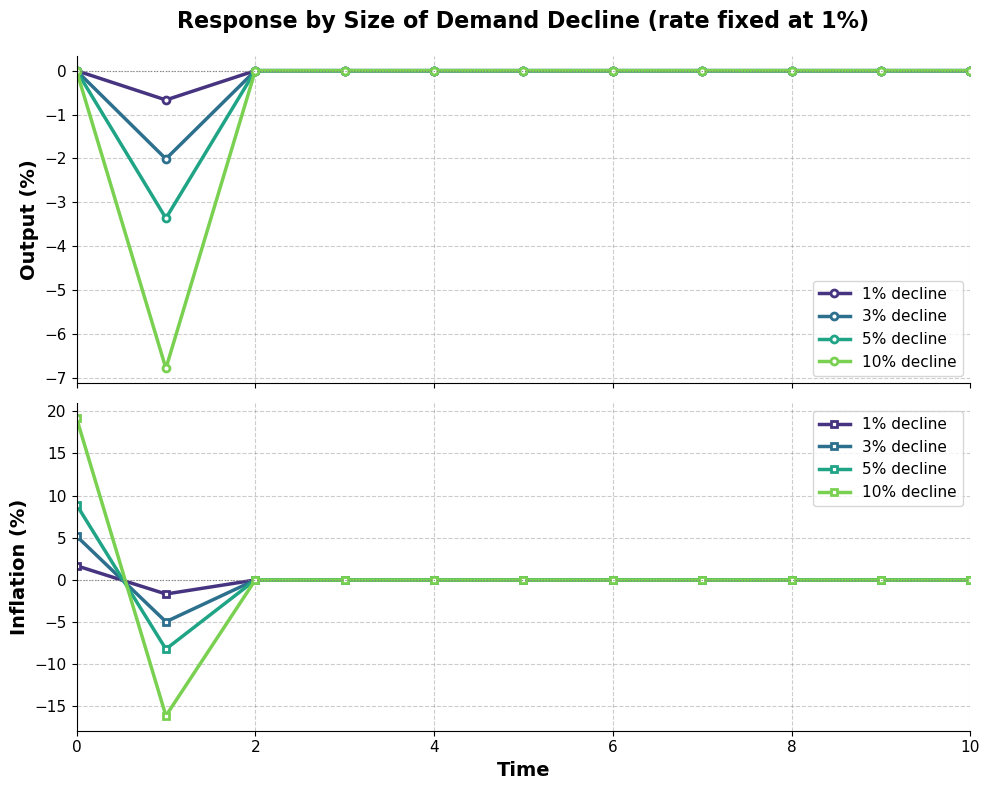

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(SHOCK_SIZES)))

for s, col in zip(SHOCK_SIZES, colors):
    Y_s, pi_s = solve(s, P_flat, R_SS)
    lab = f'{100*(1-s):.0f}% decline'
    ax1.plot(100 * Y_s,  lw=2.5, marker='o', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    ax2.plot(100 * pi_s, lw=2.5, marker='s', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)

ax1.set_title('Response by Size of Demand Decline (rate fixed at 1%)',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Output (%)', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation (%)', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 10)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=11)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../demand_shock_sizes.png', dpi=150)
plt.show()

## Why every panel has the same shape

With the rate fixed the price index never moves, so the whole response is the shifter passed
through the consumption function and the Euler equation:

$$\log(1+Y_1)=\frac{1}{\gamma+\eta}\,\log\theta_1,
\qquad
\log(1+\pi_0)=\log\!\big(\beta_{hh}(1+r)\big)-\Big(1+\frac{\gamma}{\gamma+\eta}\Big)\log\theta_1 .$$

Both are **linear in $\log\theta_1$**. Doubling the log shock doubles the log response exactly, at
any magnitude — so "different demand shock levels" is a one-parameter family, not a set of
qualitatively different experiments. The constant $\log(\beta_{hh}(1+r))=-10^{-4}$ is the
steady-state inflation drift visible in the unshocked periods above; it has to be netted out
before the proportionality is exact.

In [8]:
const = np.log(beta_hh * (1 + R_SS))
coef  = -(1 + gamma / (gamma + eta))

print(f'{"shock":>7}{"log Y_1":>12}{"closed form":>14}{"log(1+pi_0)":>14}{"closed form":>14}')
print('-' * 61)
for s in [0.99, 0.97, 0.95, 0.90, 0.80]:
    Y_s, pi_s = solve(s, P_flat, R_SS)
    ly, lp = np.log1p(Y_s[T_SHOCK]), np.log1p(pi_s[0])
    ly_cf  = np.log(s) / (gamma + eta)
    lp_cf  = const + coef * np.log(s)
    assert np.isclose(ly, ly_cf) and np.isclose(lp, lp_cf)
    print(f'{100*(1-s):>6.0f}%{ly:>12.6f}{ly_cf:>14.6f}{lp:>14.6f}{lp_cf:>14.6f}')

print('\nboth closed forms hold to machine precision at every magnitude')

  shock     log Y_1   closed form   log(1+pi_0)   closed form
-------------------------------------------------------------
     1%   -0.006700     -0.006700      0.016651      0.016651
     3%   -0.020306     -0.020306      0.050665      0.050665
     5%   -0.034196     -0.034196      0.085389      0.085389
    10%   -0.070240     -0.070240      0.175501      0.175501
    20%   -0.148762     -0.148762      0.371806      0.371806

both closed forms hold to machine precision at every magnitude


## Where size does matter: net terms

Exact proportionality in logs is convexity in levels. Two things follow, and both are invisible
at the 1–3% shocks the other notebooks use:

- the **percentage** response grows faster than the shock — going from a 1% to a 20% decline is
  22× larger in logs, but the net impact inflation spike grows 27× (1.68% to 45.04%);
- the impact inflation spike and its reversal no longer cancel. $\pi_0+\pi_1$ is a **net price
  level drift** left behind by a shock that is itself fully transitory, and it is second order in
  the shock size: 0.008% at a 1% decline, 14.0% at a 20% decline.

In [9]:
SZ = 1 - np.linspace(0.002, 0.20, 60)

trough = np.array([solve(s, P_flat, R_SS)[0].min() for s in SZ])
spike  = np.array([solve(s, P_flat, R_SS)[1][0]   for s in SZ])
rev    = np.array([solve(s, P_flat, R_SS)[1][1]   for s in SZ])
drift  = spike + rev

print(f'{"shock":>7}{"Y trough":>12}{"linear":>10}{"spike":>10}{"|reversal|":>12}{"drift":>10}')
print('-' * 61)
for s in [0.99, 0.95, 0.90, 0.85, 0.80]:
    Y_s, pi_s = solve(s, P_flat, R_SS)
    lin = (1 - s) / (gamma + eta)                      # first-order approximation
    print(f'{100*(1-s):>6.0f}%{100*Y_s.min():>11.4f}%{-100*lin:>9.4f}%{100*pi_s[0]:>9.4f}%'
          f'{-100*pi_s[1]:>11.4f}%{100*(pi_s[0]+pi_s[1]):>9.4f}%')

  shock    Y trough    linear     spike  |reversal|     drift
-------------------------------------------------------------
     1%    -0.6678%  -0.6667%   1.6790%     1.6709%   0.0081%
     5%    -3.3617%  -3.3333%   8.9140%     8.2028%   0.7112%
    10%    -6.7830%  -6.6667%  19.1843%    16.1131%   3.0712%
    15%   -10.2683% -10.0000%  31.0967%    23.7357%   7.3610%
    20%   -13.8226% -13.3333%  45.0351%    31.0650%  13.9702%


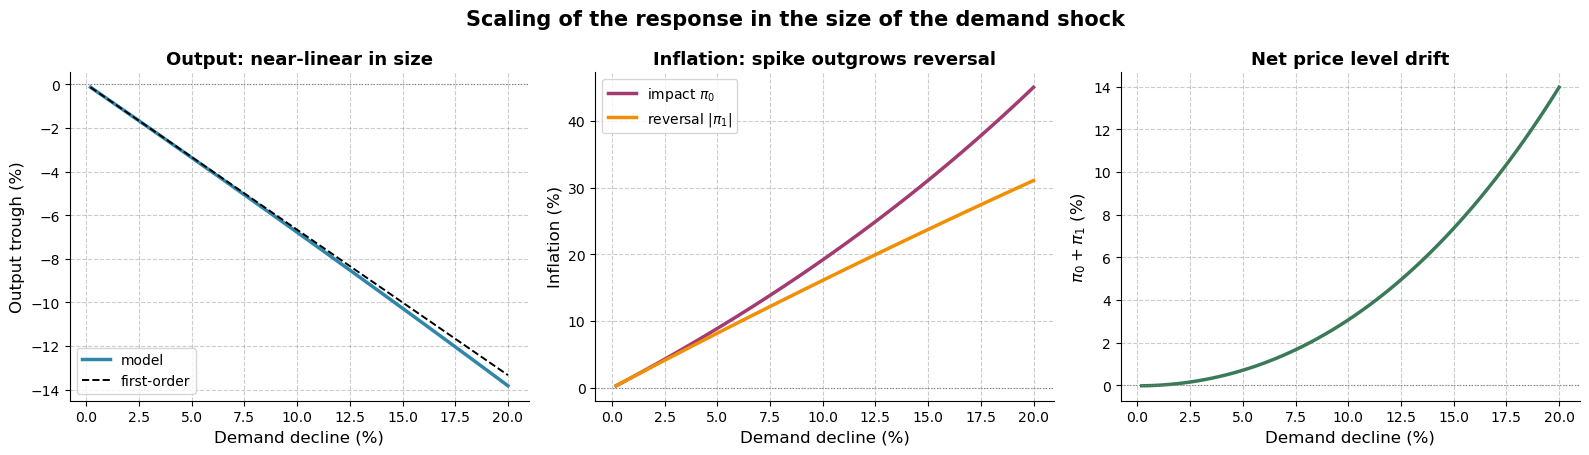

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
x = 100 * (1 - SZ)

ax = axes[0]
ax.plot(x, 100 * trough, color='#2E86AB', lw=2.5, label='model')
ax.plot(x, -x / (gamma + eta), 'k--', lw=1.4, label='first-order')
ax.set_xlabel('Demand decline (%)', fontsize=12)
ax.set_ylabel('Output trough (%)', fontsize=12)
ax.set_title('Output: near-linear in size', fontsize=13, weight='bold')
ax.legend(fontsize=10)

ax = axes[1]
ax.plot(x,  100 * spike, color='#A23B72', lw=2.5, label=r'impact $\pi_0$')
ax.plot(x, -100 * rev,   color='#F18F01', lw=2.5, label=r'reversal $|\pi_1|$')
ax.set_xlabel('Demand decline (%)', fontsize=12)
ax.set_ylabel('Inflation (%)', fontsize=12)
ax.set_title('Inflation: spike outgrows reversal', fontsize=13, weight='bold')
ax.legend(fontsize=10)

ax = axes[2]
ax.plot(x, 100 * drift, color='#3B7A57', lw=2.5)
ax.set_xlabel('Demand decline (%)', fontsize=12)
ax.set_ylabel(r'$\pi_0+\pi_1$ (%)', fontsize=12)
ax.set_title('Net price level drift', fontsize=13, weight='bold')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Scaling of the response in the size of the demand shock',
             fontsize=15, weight='bold')
plt.tight_layout()
plt.savefig('../demand_shock_sizes_scaling.png', dpi=150)
plt.show()

## Policy

Everything above holds the rate at 1%. Letting it move is where the shock size stops being a pure
rescaling, because the rate feeds back into the *price* path: a different rate changes
$\tau^*=-1/\log(\beta c)-N$, firms re-time, and the price index moves as cohorts switch over.

`price_path` is the per-rate loop of `fixed_demand_shock.ipynb` pulled out into a function. At each
date `j` firms with `tau > j` have not yet re-optimised and still price off `beta_org`, while those
with `tau_rep <= j` have switched to `beta_rep`; where a firm appears in both, the higher
$\beta^{t}(t+N)$ wins. Paths are padded to a common horizon so losses are comparable across rates.

In [11]:
def price_path(r, H=H):
    '''CES price index over time when the policy rate moves from R_SS to r.'''
    beta_org = c / (1 + R_SS)
    beta_rep = c / (1 + r)
    t_org = round_tau(beta_org, N).sort_values()
    t_rep = round_tau(beta_rep, N).sort_values()

    P = np.zeros(H)
    P[0] = (np.sum(1 / np.array(beta_org ** t_org * (t_org + N)) ** (1 - sigma))) ** (1 / (1 - sigma))
    P_end = (np.sum(1 / np.array(beta_rep ** t_rep * (t_rep + N)) ** (1 - sigma))) ** (1 / (1 - sigma))

    jmax = int(np.max(t_rep))
    for j in range(0, jmax + 1):
        a = t_org[t_org > j].to_frame(name='t'); a['source'] = 'org'
        b = t_rep[t_rep <= j].to_frame(name='t'); b['source'] = 'rep'
        tt = pd.concat([a, b])

        dup, keep = tt.index[tt.index.duplicated(keep=False)].unique(), []
        for i in dup:
            rows  = tt.loc[[i]]
            N_i   = N.loc[[i]]
            v_org = beta_org ** rows[rows['source'] == 'org']['t'].values[0] * \
                    (rows[rows['source'] == 'org']['t'].values[0] + N_i)
            v_rep = beta_rep ** rows[rows['source'] == 'rep']['t'].values[0] * \
                    (rows[rows['source'] == 'rep']['t'].values[0] + N_i)
            keep.append(rows[rows['source'] == ('org' if v_org.values >= v_rep.values else 'rep')])

        tt = tt[~tt.index.isin(dup)]
        if keep:
            tt = pd.concat([tt] + keep)
        tt['N'] = N.loc[tt.index].values
        bvec = tt['source'].map({'org': beta_org, 'rep': beta_rep})
        tp   = (bvec ** tt['t'] * (tt['t'] + tt['N'])).values
        if j + 1 < H:
            P[j + 1] = (np.sum(1 / tp ** (1 - sigma))) ** (1 / (1 - sigma))

    P[min(jmax + 1, H - 1)] = P_end
    P[min(jmax + 2, H):] = P_end                    # pad the tail with the re-optimised index
    return P


assert np.allclose(price_path(R_SS), P_flat), 'r = R_SS must leave the price index flat'
print('price index flat at the steady-state rate, as it must be')

price index flat at the steady-state rate, as it must be


In [12]:
R_GRID = np.linspace(0.0, 0.02, 101)
P_GRID = np.array([price_path(r) for r in R_GRID])
K_SS   = int(np.argmin(np.abs(R_GRID - R_SS)))
print(f'{len(R_GRID)} rate paths built; steady-state rate at grid index {K_SS} '
      f'(r = {R_GRID[K_SS]:.4f})')

101 rate paths built; steady-state rate at grid index 50 (r = 0.0100)


### The rate that minimises each loss

Same losses as `fixed_demand_shock.ipynb`: $\sum_t Y_t^2$, $\sum_t \pi_t^2$, and their sum.

In [13]:
def losses(shock):
    '''Output-only, inflation-only and combined loss at every rate on the grid.'''
    Lo = np.zeros(len(R_GRID)); Lp = np.zeros(len(R_GRID))
    for k, r in enumerate(R_GRID):
        Y_k, pi_k = solve(shock, P_GRID[k], r)
        Lo[k], Lp[k] = np.sum(Y_k ** 2), np.sum(pi_k ** 2)
    return Lo, Lp, Lo + Lp


SZ_POL = 1 - np.linspace(0.005, 0.15, 20)
pol = []
for s in SZ_POL:
    Lo, Lp, L = losses(s)
    pol.append(dict(s=s, r_out=R_GRID[Lo.argmin()], r_pi=R_GRID[Lp.argmin()],
                    r_both=R_GRID[L.argmin()], gain=1 - L.min() / L[K_SS]))

print(f'{"shock":>7}{"r* output":>12}{"r* inflation":>15}{"r* combined":>14}{"loss reduction":>17}')
print('-' * 65)
for p in pol:
    print(f'{100*(1-p["s"]):>6.1f}%{100*p["r_out"]:>11.3f}%{100*p["r_pi"]:>14.3f}%'
          f'{100*p["r_both"]:>13.3f}%{100*p["gain"]:>16.2f}%')

  shock   r* output   r* inflation   r* combined   loss reduction
-----------------------------------------------------------------
   0.5%      1.000%         0.940%        0.980%            8.74%
   1.3%      1.000%         0.940%        0.940%           12.19%
   2.0%      1.000%         0.940%        0.940%           11.94%
   2.8%      1.000%         0.820%        0.940%            9.94%
   3.6%      1.000%         0.820%        0.940%            8.28%
   4.3%      1.000%         0.820%        0.940%            7.01%
   5.1%      1.000%         0.760%        0.940%            6.03%
   5.8%      1.000%         0.760%        0.940%            5.25%
   6.6%      1.000%         0.760%        0.940%            4.63%
   7.4%      1.000%         0.760%        0.940%            4.12%
   8.1%      1.000%         0.760%        0.940%            3.69%
   8.9%      1.000%         0.760%        0.940%            3.33%
   9.7%      1.000%         0.380%        0.940%            3.03%
  10.4%   

In [14]:
assert np.allclose([p['r_out'] for p in pol], R_SS), \
    'output-only optimum should sit at the steady-state rate at every size'
print('The output-minimising rate is the steady-state rate at every magnitude.')
print('Prices are pre-set when the shock lands, so no rate can touch the impact trough;')
print('moving the rate only re-times firms and distorts the periods after it.')

The output-minimising rate is the steady-state rate at every magnitude.
Prices are pre-set when the shock lands, so no rate can touch the impact trough;
moving the rate only re-times firms and distorts the periods after it.


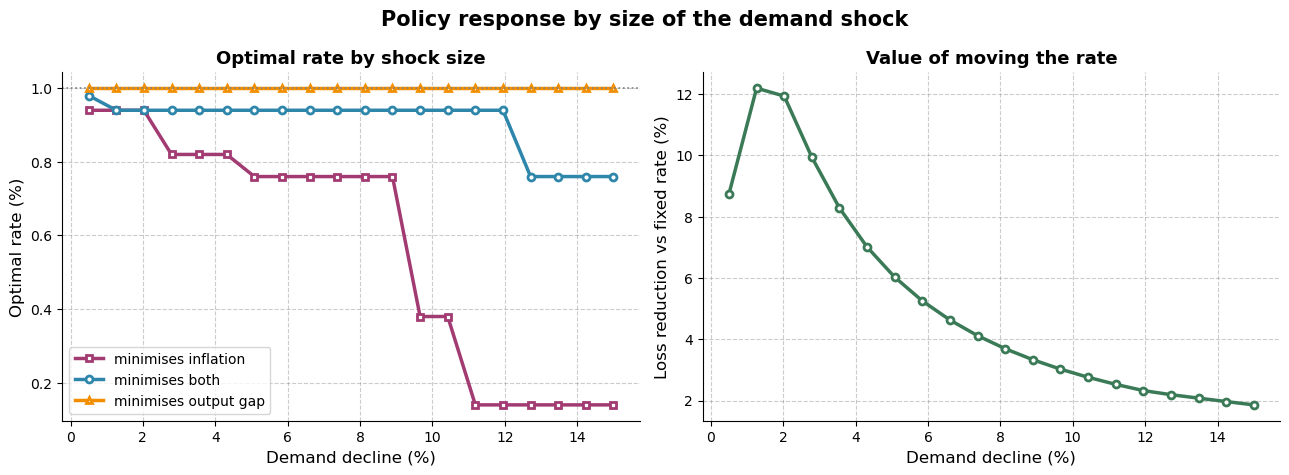

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
xp = 100 * (1 - np.array([p['s'] for p in pol]))

ax = axes[0]
ax.plot(xp, [100 * p['r_pi']   for p in pol], color='#A23B72', lw=2.5, marker='s',
        markersize=5, markerfacecolor='white', markeredgewidth=2, label='minimises inflation')
ax.plot(xp, [100 * p['r_both'] for p in pol], color='#2E86AB', lw=2.5, marker='o',
        markersize=5, markerfacecolor='white', markeredgewidth=2, label='minimises both')
ax.plot(xp, [100 * p['r_out']  for p in pol], color='#F18F01', lw=2.5, marker='^',
        markersize=5, markerfacecolor='white', markeredgewidth=2, label='minimises output gap')
ax.axhline(100 * R_SS, color='gray', linestyle=':', lw=1.2)
ax.set_xlabel('Demand decline (%)', fontsize=12)
ax.set_ylabel('Optimal rate (%)', fontsize=12)
ax.set_title('Optimal rate by shock size', fontsize=13, weight='bold')
ax.legend(fontsize=10)

ax = axes[1]
ax.plot(xp, [100 * p['gain'] for p in pol], color='#3B7A57', lw=2.5, marker='o',
        markersize=5, markerfacecolor='white', markeredgewidth=2)
ax.set_xlabel('Demand decline (%)', fontsize=12)
ax.set_ylabel('Loss reduction vs fixed rate (%)', fontsize=12)
ax.set_title('Value of moving the rate', fontsize=13, weight='bold')

for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Policy response by size of the demand shock', fontsize=15, weight='bold')
plt.tight_layout()
plt.savefig('../demand_shock_sizes_policy.png', dpi=150)
plt.show()

### Paths under the combined-loss optimum

  shock       r*   Y trough fixed   Y trough opt
------------------------------------------------
     1%    0.94%         -0.6678%       -0.7437%
     3%    0.94%         -2.0101%       -2.0101%
     5%    0.94%         -3.3617%       -3.3617%
    10%    0.94%         -6.7830%       -6.7830%


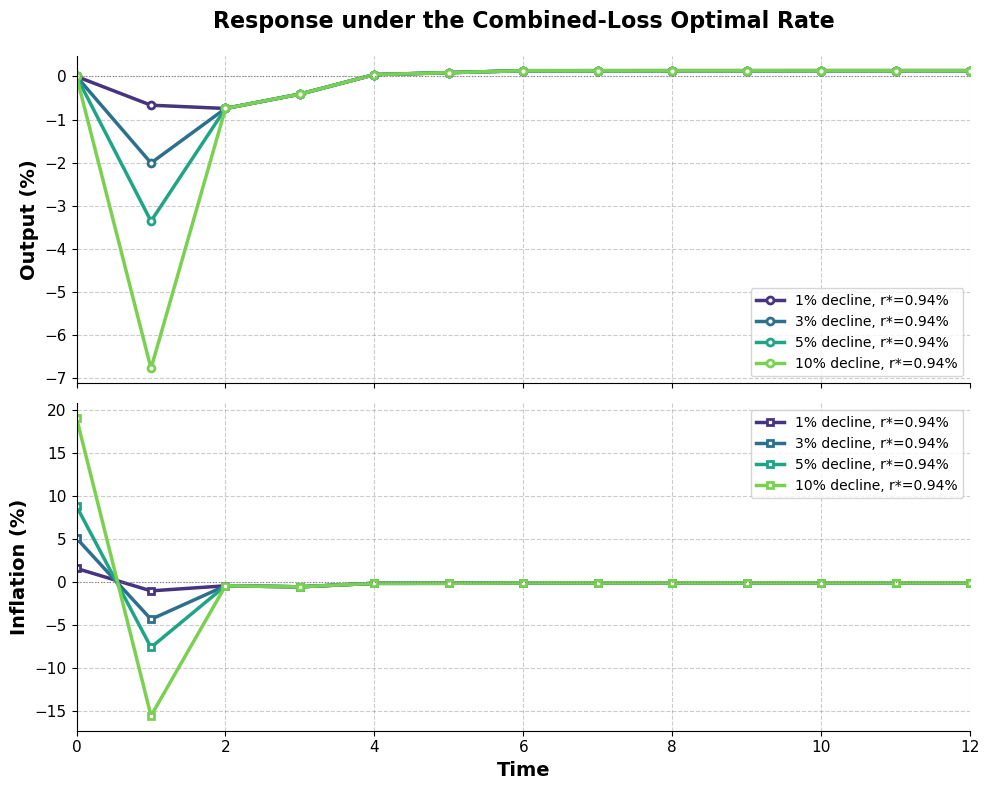

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
colors = plt.cm.viridis(np.linspace(0.15, 0.8, len(SHOCK_SIZES)))

print(f'{"shock":>7}{"r*":>9}{"Y trough fixed":>17}{"Y trough opt":>15}')
print('-' * 48)
for s, col in zip(SHOCK_SIZES, colors):
    Lo, Lp, L = losses(s)
    k = int(L.argmin())
    Y_f, _    = solve(s, P_GRID[K_SS], R_GRID[K_SS])
    Y_o, pi_o = solve(s, P_GRID[k], R_GRID[k])
    lab = f'{100*(1-s):.0f}% decline, r*={100*R_GRID[k]:.2f}%'
    ax1.plot(100 * Y_o,  lw=2.5, marker='o', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    ax2.plot(100 * pi_o, lw=2.5, marker='s', markersize=5, color=col,
             markerfacecolor='white', markeredgewidth=2, label=lab)
    print(f'{100*(1-s):>6.0f}%{100*R_GRID[k]:>8.2f}%{100*Y_f.min():>16.4f}%{100*Y_o.min():>14.4f}%')

ax1.set_title('Response under the Combined-Loss Optimal Rate',
              fontsize=16, weight='bold', pad=20)
ax1.set_ylabel('Output (%)', fontsize=14, weight='bold')
ax2.set_ylabel('Inflation (%)', fontsize=14, weight='bold')
ax2.set_xlabel('Time', fontsize=14, weight='bold')

for ax in (ax1, ax2):
    ax.set_xlim(0, 12)
    ax.grid(True, linestyle='--', alpha=0.4, color='gray')
    ax.tick_params(axis='both', which='major', labelsize=11)
    ax.axhline(0, color='gray', linestyle=':', linewidth=0.8)
    ax.legend(fontsize=10)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('../demand_shock_sizes_optimal.png', dpi=150)
plt.show()

## Summary

- With the rate fixed, the demand shock's effect is **exactly linear in $\log\theta_1$** for both
  output and inflation. Every panel in the first figure is the same path rescaled, and the closed
  forms hold to machine precision from a 1% to a 20% decline. Nothing in the time-to-produce
  structure creates a size-dependent shape, because a demand shock does not move any firm's
  optimal lag $\tau^*=-1/\log(\beta c)-N$.
- The size-dependence that does exist is the **convexity of $\exp$**: the impact inflation spike
  grows faster than its reversal, leaving a net price level drift of 0.008% after a 1% decline but
  14.0% after a 20% decline. Below about 5% this is small enough to ignore, which is why the other
  notebooks' 1–3% shocks never surface it.
- **Policy is the exception.** The output-minimising rate is the steady-state rate at every
  magnitude — prices are already set when the shock lands, so the impact trough is untouchable and
  moving the rate only re-times firms in later periods. The inflation-minimising rate falls
  steeply with the shock, in discrete steps (0.94% → 0.82% → 0.76% → 0.38% → 0.14%): `tau` is
  integer-valued, so the price path only responds when a rate change is large enough to flip a
  cohort of firms to a different lag.
- The **value** of moving the rate falls as the shock grows — 12.2% of the loss at a 1.3% decline,
  1.9% at a 15% decline. The output loss is the part policy cannot touch, and it grows quadratically
  in the shock, so it swamps the inflation loss that policy can trade against.

**Caveats.** The rate here is a single constant from $t=0$ onward, not a sequence — the
`generate_rate_combinations` experiments elsewhere in the repo are the right comparison for a path.
The shock is one period at $t=1$; persistence is a separate margin, handled in
`persistence_demand.ipynb`. And $\eta=0.5$ is inherited from `fixed_demand_shock.ipynb`, not the
$\eta=2$ used in the `semi_endo/` notebooks — the proportionality result is independent of it, but
the magnitudes are not.